In [1]:
!pip -q install pandas numpy networkx matplotlib geopandas shapely pyogrio

In [2]:
from google.colab import files
import os

required_files = [
    "colombo_nodes.csv",
    "colombo_roads.csv",
    "colombo_bridge_edges.csv"
]

missing_files = [
    f for f in required_files if not os.path.exists(f)
]

if missing_files:
    uploaded = files.upload()

for f in required_files:
    if not os.path.exists(f):
        raise FileNotFoundError(
            f"{f} is missing. Please upload it and rerun this cell."
        )

print("All three required CSV files are available.")

Saving colombo_bridge_edges.csv to colombo_bridge_edges.csv
Saving colombo_roads.csv to colombo_roads.csv
Saving colombo_nodes.csv to colombo_nodes.csv
All three required CSV files are available.


In [3]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import random
import os

nodes = pd.read_csv("colombo_nodes.csv")
roads = pd.read_csv("colombo_roads.csv")
bridges = pd.read_csv("colombo_bridge_edges.csv")

print("NODES:", nodes.shape)
display(nodes.head())

print("ROADS:", roads.shape)
display(roads.head())

print("SAVED BRIDGE EDGES:", bridges.shape)
display(bridges.head())

# Check required columns
assert {"osmid", "x", "y"}.issubset(nodes.columns), \
    "Nodes CSV must contain osmid, x, and y columns."

assert {"u", "v"}.issubset(roads.columns), \
    "Roads CSV must contain u and v columns."

assert {"from_node", "to_node"}.issubset(bridges.columns), \
    "Bridge CSV must contain from_node and to_node columns."

print("Dataset column checks passed.")

NODES: (1737, 5)


,osmid,y,x,street_count,highway
0,60796641,6.909574,79.866169,3,NaN
1,60796643,6.909414,79.871819,4,NaN
2,60796645,6.909296,79.876801,5,NaN
3,61802472,6.943806,79.878178,4,traffic_signals
4,61802753,6.909286,79.860754,3,NaN


ROADS: (3633, 9)


,u,v,key,osmid,name,highway,length,oneway,maxspeed
0,60796641,2419600689,0,8111662,Gregory's Road,tertiary,47.055057,False,40
1,60796641,2419532369,0,143399474,Maitland Crescent,secondary,94.513294,False,40
2,60796643,679008490,0,233499011,R.G. Senanayake Mawatha (Gregory's Road),tertiary,104.029506,False,40
3,60796643,5375518034,0,233499011,R.G. Senanayake Mawatha (Gregory's Road),tertiary,50.020610,False,40
4,60796643,127658294,0,"[356689196, 487441125]",Wijerama Mawatha (McCarthy Road),secondary,245.913866,False,50


SAVED BRIDGE EDGES: (398, 2)


,from_node,to_node
0,61802472,1131883011
1,191799460,9485495161
2,191799826,6512958357
3,208540781,1839445251
4,269202338,1839445109


Dataset column checks passed.


In [4]:
G = nx.from_pandas_edgelist(
    roads,
    source="u",
    target="v",
    edge_attr=True,
    create_using=nx.Graph()
)

# Ensure the saved bridge IDs have compatible numeric types
bridges["from_node"] = pd.to_numeric(
    bridges["from_node"], errors="raise"
).astype("int64")

bridges["to_node"] = pd.to_numeric(
    bridges["to_node"], errors="raise"
).astype("int64")

print("Graph nodes:", G.number_of_nodes())
print("Unique graph edges:", G.number_of_edges())
print("CSV node records:", len(nodes))
print("CSV road records:", len(roads))

Graph nodes: 1737
Unique graph edges: 2318
CSV node records: 1737
CSV road records: 3633


In [5]:
calculated_bridges = {
    frozenset((u, v))
    for u, v in nx.bridges(G)
}

saved_bridges = {
    frozenset((int(u), int(v)))
    for u, v in bridges[
        ["from_node", "to_node"]
    ].itertuples(index=False, name=None)
}

print("Calculated bridge edges:", len(calculated_bridges))
print("Saved bridge records:", len(bridges))
print("Unique saved bridge edges:", len(saved_bridges))
print("Matching bridge edges:",
      len(calculated_bridges & saved_bridges))
print("All saved edges match:",
      calculated_bridges == saved_bridges)

Calculated bridge edges: 398
Saved bridge records: 398
Unique saved bridge edges: 398
Matching bridge edges: 398
All saved edges match: True


In [6]:
def network_metrics(graph, scenario):
    components = list(nx.connected_components(graph))
    largest_size = max((len(c) for c in components), default=0)
    node_count = graph.number_of_nodes()

    return {
        "scenario": scenario,
        "nodes": node_count,
        "edges": graph.number_of_edges(),
        "connected_components": len(components),
        "largest_component_nodes": largest_size,
        "largest_component_percent": (
            100 * largest_size / node_count if node_count else 0
        ),
        "fully_connected": nx.is_connected(graph)
            if node_count else False
    }

baseline_result = network_metrics(G, "Baseline")
baseline_df = pd.DataFrame([baseline_result])

display(baseline_df)
baseline_df.to_csv("baseline_network_summary.csv", index=False)

,scenario,nodes,edges,connected_components,largest_component_nodes,largest_component_percent,fully_connected
0,Baseline,1737,2318,1,1737,100.0,True


In [7]:
G_bridge_removed = G.copy()

# Remove only edges that actually exist in G
valid_bridge_edges = [
    (u, v)
    for edge in calculated_bridges
    for u, v in [tuple(edge)]
    if G.has_edge(u, v)
]

G_bridge_removed.remove_edges_from(valid_bridge_edges)

bridge_result = network_metrics(
    G_bridge_removed, "All bridge edges removed"
)

print("Bridge edges removed:", len(valid_bridge_edges))
display(pd.DataFrame([bridge_result]))

Bridge edges removed: 398


,scenario,nodes,edges,connected_components,largest_component_nodes,largest_component_percent,fully_connected
0,All bridge edges removed,1737,1920,399,1334,76.799079,False


In [8]:
edge_bc = nx.edge_betweenness_centrality(
    G,
    normalized=True
)

centrality_rows = []

for (u, v), score in edge_bc.items():
    attributes = G[u][v]
    road_name = attributes.get("name")

    centrality_rows.append({
        "from_node": u,
        "to_node": v,
        "edge_betweenness": score,
        "road_name": road_name,
        "is_bridge": frozenset((u, v)) in calculated_bridges
    })

centrality_df = pd.DataFrame(centrality_rows)

centrality_df = centrality_df.sort_values(
    "edge_betweenness", ascending=False
).reset_index(drop=True)

display(centrality_df.head(20))
centrality_df.to_csv("colombo_edge_betweenness.csv", index=False)

threshold_95 = centrality_df["edge_betweenness"].quantile(0.95)

critical_roads = centrality_df[
    centrality_df["edge_betweenness"] >= threshold_95
].copy()

print("95th percentile centrality threshold:", threshold_95)
print("Edges selected for targeted closure:", len(critical_roads))

,from_node,to_node,edge_betweenness,road_name,is_bridge
0,127657253,6234353185,0.166788,T. B. Jayah Mawatha,False
1,663253013,6233616394,0.149763,NaN,False
2,3136316335,5261493138,0.148682,Orabi Pasha Mawatha,False
3,6233616394,6233578621,0.142718,"['P De S Kularatne Mawatha', 'P. de S. Kularat...",False
4,6234353217,6234353185,0.134640,Dr. Colvin R. de Silva Mawatha (Union Place),False
5,270333409,10629326906,0.126486,NaN,False
6,1863456310,3799736775,0.123938,Olcott Mawatha,False
7,6234353209,11541825548,0.123598,T. B. Jayah Mawatha,False
8,2320511891,13663630398,0.123465,Panchikawatte Road,False
9,127657253,662875960,0.121444,T. B. Jayah Mawatha,False


95th percentile centrality threshold: 0.05236535196847245
Edges selected for targeted closure: 116


In [9]:
random.seed(42)

targeted_edges = list(zip(
    critical_roads["from_node"],
    critical_roads["to_node"]
))

G_targeted = G.copy()
G_targeted.remove_edges_from(targeted_edges)

number_to_remove = len(targeted_edges)
random_edges = random.sample(list(G.edges()), number_to_remove)

G_random = G.copy()
G_random.remove_edges_from(random_edges)

comparison_df = pd.DataFrame([
    network_metrics(G, "Baseline"),
    network_metrics(G_bridge_removed, "All bridge edges removed"),
    network_metrics(G_targeted, "Top 5% betweenness removed"),
    network_metrics(G_random, "Random edges removed")
])

display(comparison_df)
comparison_df.to_csv("network_closure_comparison.csv", index=False)

,scenario,nodes,edges,connected_components,largest_component_nodes,largest_component_percent,fully_connected
0,Baseline,1737,2318,1,1737,100.000000,True
1,All bridge edges removed,1737,1920,399,1334,76.799079,False
2,Top 5% betweenness removed,1737,2202,28,1690,97.294185,False
3,Random edges removed,1737,2202,22,1703,98.042602,False


In [10]:
random.seed(42)

closure_levels = [0.05, 0.10, 0.15]
repetitions = 30
random_results = []

edge_list = list(G.edges())

for fraction in closure_levels:
    number_to_remove = int(len(edge_list) * fraction)

    for repeat in range(repetitions):
        chosen_edges = random.sample(edge_list, number_to_remove)

        test_graph = G.copy()
        test_graph.remove_edges_from(chosen_edges)

        result = network_metrics(
            test_graph,
            f"{fraction:.0%} random closure"
        )

        result["closure_fraction"] = fraction
        result["repeat"] = repeat + 1
        random_results.append(result)

random_closure_df = pd.DataFrame(random_results)

random_summary = (
    random_closure_df
    .groupby("closure_fraction")
    .agg(
        mean_components=("connected_components", "mean"),
        std_components=("connected_components", "std"),
        mean_largest_component_percent=(
            "largest_component_percent", "mean"
        ),
        std_largest_component_percent=(
            "largest_component_percent", "std"
        )
    )
    .reset_index()
)

display(random_summary)

random_closure_df.to_csv("random_closure_all_runs.csv", index=False)
random_summary.to_csv("random_closure_summary.csv", index=False)

,closure_fraction,mean_components,std_components,mean_largest_component_percent,std_largest_component_percent
0,0.05,23.600000,4.005169,97.605066,0.873702
1,0.10,50.533333,6.626662,93.661485,2.084106
2,0.15,84.533333,6.791137,87.526386,2.384662


In [11]:
random.seed(42)

largest_baseline_component = max(
    nx.connected_components(G), key=len
)

journey_nodes = list(largest_baseline_component)

if len(journey_nodes) < 2:
    raise ValueError("Not enough connected nodes to generate journeys.")

journeys = [
    tuple(random.sample(journey_nodes, 2))
    for _ in range(500)
]

scenarios = {
    "Baseline": G,
    "All bridge edges removed": G_bridge_removed,
    "Top 5% betweenness removed": G_targeted,
    "Random edges removed": G_random
}

journey_results = []

for name, graph in scenarios.items():
    reachable = sum(
        nx.has_path(graph, origin, destination)
        for origin, destination in journeys
    )

    journey_results.append({
        "scenario": name,
        "journeys_tested": len(journeys),
        "reachable_journeys": reachable,
        "unreachable_journeys": len(journeys) - reachable,
        "reachability_percent": 100 * reachable / len(journeys)
    })

journey_df = pd.DataFrame(journey_results)

display(journey_df)
journey_df.to_csv("journey_reachability_results.csv", index=False)

,scenario,journeys_tested,reachable_journeys,unreachable_journeys,reachability_percent
0,Baseline,500,500,0,100.0
1,All bridge edges removed,500,314,186,62.8
2,Top 5% betweenness removed,500,475,25,95.0
3,Random edges removed,500,479,21,95.8


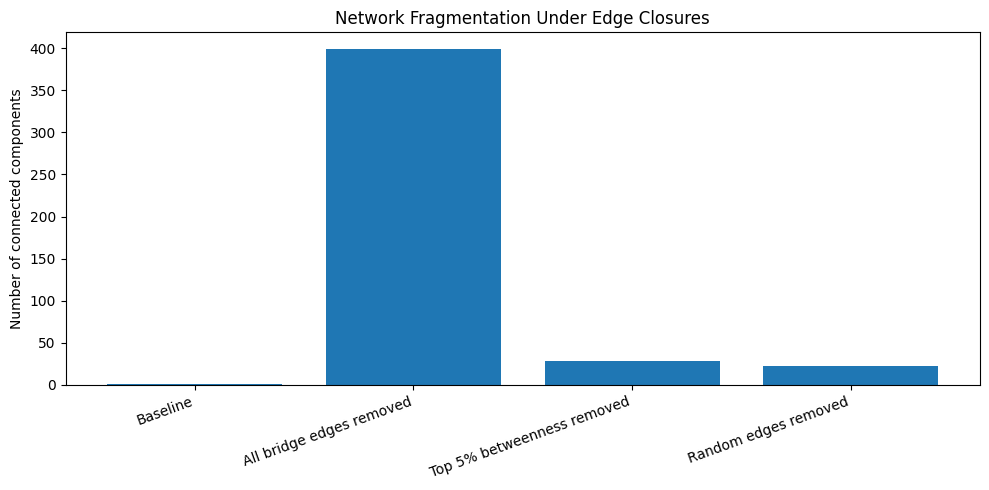

In [12]:
plt.figure(figsize=(10, 5))
plt.bar(
    comparison_df["scenario"],
    comparison_df["connected_components"]
)
plt.ylabel("Number of connected components")
plt.title("Network Fragmentation Under Edge Closures")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig("connected_components_comparison.png", dpi=300)
plt.show()

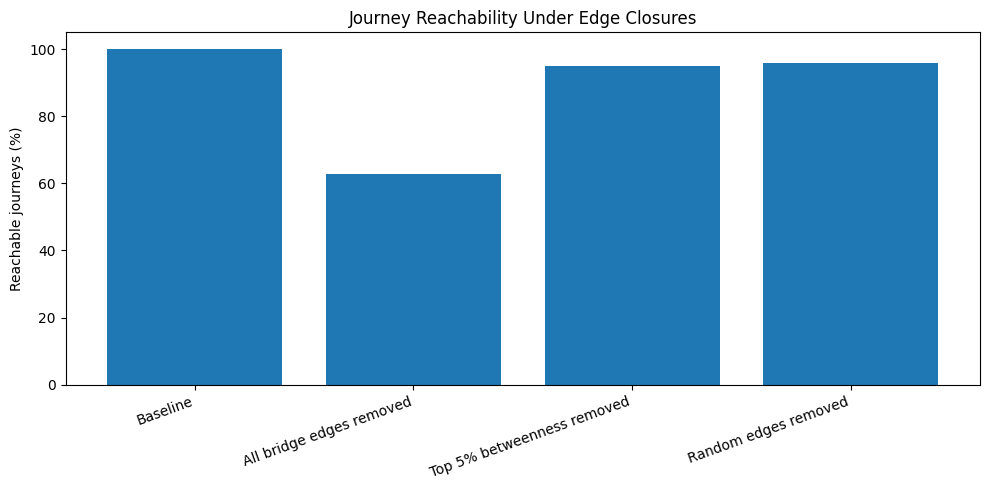

In [13]:
plt.figure(figsize=(10, 5))
plt.bar(
    journey_df["scenario"],
    journey_df["reachability_percent"]
)
plt.ylabel("Reachable journeys (%)")
plt.ylim(0, 105)
plt.title("Journey Reachability Under Edge Closures")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig("journey_reachability_comparison.png", dpi=300)
plt.show()

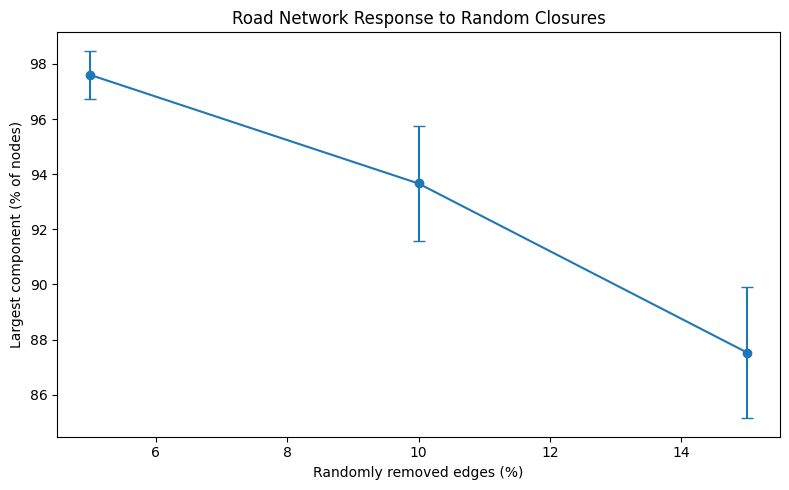

In [14]:
plt.figure(figsize=(8, 5))
plt.errorbar(
    random_summary["closure_fraction"] * 100,
    random_summary["mean_largest_component_percent"],
    yerr=random_summary["std_largest_component_percent"],
    marker="o",
    capsize=4
)
plt.xlabel("Randomly removed edges (%)")
plt.ylabel("Largest component (% of nodes)")
plt.title("Road Network Response to Random Closures")
plt.tight_layout()
plt.savefig("random_closure_robustness.png", dpi=300)
plt.show()

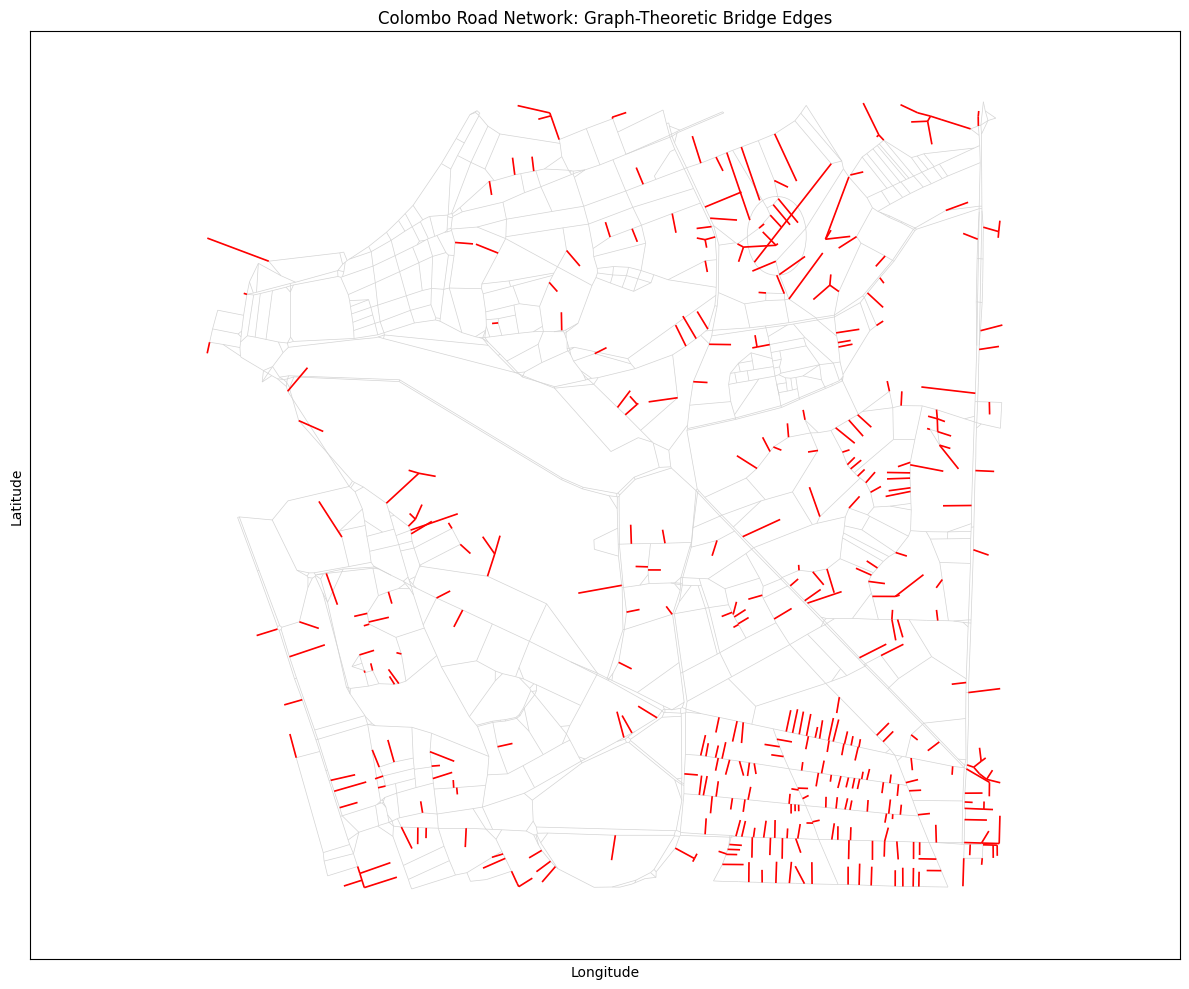

In [15]:
# Use node coordinates from the CSV
nodes["osmid"] = pd.to_numeric(nodes["osmid"], errors="raise").astype("int64")

pos = {
    int(row.osmid): (float(row.x), float(row.y))
    for row in nodes.itertuples()
    if pd.notna(row.x) and pd.notna(row.y)
}

mapped_edges = [
    (u, v) for u, v in G.edges()
    if u in pos and v in pos
]

mapped_bridges = [
    (u, v) for edge in calculated_bridges
    for u, v in [tuple(edge)]
    if u in pos and v in pos
]

plt.figure(figsize=(12, 10))

nx.draw_networkx_edges(
    G, pos, edgelist=mapped_edges,
    edge_color="lightgray", width=0.5
)

nx.draw_networkx_edges(
    G, pos, edgelist=mapped_bridges,
    edge_color="red", width=1.2
)

plt.title("Colombo Road Network: Graph-Theoretic Bridge Edges")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.axis("equal")
plt.tight_layout()
plt.savefig("colombo_bridge_analysis_map.png", dpi=300)
plt.show()

In [16]:
import geopandas as gpd
from shapely.geometry import LineString

flood_file = "colombo_flood_extent.geojson"

if not os.path.exists(flood_file):
    print(
        "Flood analysis skipped: no georeferenced flood polygon found."
    )
    print(
        "Do not classify roads as flood-exposed using the PDF image alone."
    )
else:
    # Read the flood polygon and check its coordinate system
    flood_gdf = gpd.read_file(flood_file)

    if flood_gdf.crs is None:
        raise ValueError(
            "The flood layer has no CRS. Define its correct CRS first."
        )

    flood_gdf = flood_gdf.to_crs("EPSG:32644")

    # Create road geometries from the node coordinates
    node_lookup = {
        int(row.osmid): (float(row.x), float(row.y))
        for row in nodes.itertuples()
        if pd.notna(row.x) and pd.notna(row.y)
    }

    road_geometries = []

    for row in roads.itertuples():
        u = int(row.u)
        v = int(row.v)

        if u in node_lookup and v in node_lookup:
            road_geometries.append({
                "u": u,
                "v": v,
                "road_name": getattr(row, "name", None),
                "geometry": LineString([
                    node_lookup[u], node_lookup[v]
                ])
            })

    road_gdf = gpd.GeoDataFrame(
        road_geometries, geometry="geometry", crs="EPSG:4326"
    ).to_crs("EPSG:32644")

    # Merge all flood polygons into one geometry
    flood_union = flood_gdf.geometry.union_all()

    road_gdf["flood_exposed"] = road_gdf.geometry.intersects(
        flood_union
    )

    road_gdf["flood_intersection_length_m"] = (
        road_gdf.geometry.intersection(flood_union).length
    )

    print("Road records checked:", len(road_gdf))
    print("Road records intersecting flood extent:",
          int(road_gdf["flood_exposed"].sum()))

    display(
        road_gdf[road_gdf["flood_exposed"]].head(20)
    )

    road_gdf.to_file(
        "colombo_roads_flood_exposure.gpkg",
        driver="GPKG"
    )

    road_gdf.drop(columns="geometry").to_csv(
        "colombo_roads_flood_exposure.csv",
        index=False
    )

Flood analysis skipped: no georeferenced flood polygon found.
Do not classify roads as flood-exposed using the PDF image alone.


In [17]:
flood_gpkg = "colombo_roads_flood_exposure.gpkg"

if os.path.exists(flood_gpkg):
    exposed_roads = gpd.read_file(flood_gpkg)

    exposed_edges = {
        frozenset((int(row.u), int(row.v)))
        for row in exposed_roads.itertuples()
        if row.flood_exposed
    }

    G_flood_scenario = G.copy()

    edges_to_close = [
        (u, v)
        for edge in exposed_edges
        for u, v in [tuple(edge)]
        if G_flood_scenario.has_edge(u, v)
    ]

    G_flood_scenario.remove_edges_from(edges_to_close)

    flood_metrics = network_metrics(
        G_flood_scenario,
        "Mapped flood-intersecting edges removed"
    )

    print("Mapped road records intersecting flood extent:",
          len(exposed_edges))
    print("Unique graph edges removed:", len(edges_to_close))

    display(pd.DataFrame([flood_metrics]))

    # Add this scenario to the comparison table
    comparison_with_flood = pd.concat(
        [
            comparison_df,
            pd.DataFrame([flood_metrics])
        ],
        ignore_index=True
    )

    display(comparison_with_flood)

    comparison_with_flood.to_csv(
        "network_comparison_with_flood.csv",
        index=False
    )
else:
    print("Skipped: complete Step 14 with a suitable flood layer first.")

Skipped: complete Step 14 with a suitable flood layer first.


In [18]:
import zipfile
import os

output_files = [
    "colombo_nodes.csv",
    "colombo_roads.csv",
    "colombo_bridge_edges.csv",
    "baseline_network_summary.csv",
    "colombo_edge_betweenness.csv",
    "network_closure_comparison.csv",
    "random_closure_all_runs.csv",
    "random_closure_summary.csv",
    "journey_reachability_results.csv",
    "connected_components_comparison.png",
    "journey_reachability_comparison.png",
    "random_closure_robustness.png",
    "colombo_bridge_analysis_map.png",
    "colombo_roads_flood_exposure.csv",
    "colombo_roads_flood_exposure.gpkg",
    "network_comparison_with_flood.csv"
]

zip_name = "Colombo_Graph_Theory_Research_Results.zip"

with zipfile.ZipFile(
    zip_name, "w", zipfile.ZIP_DEFLATED
) as archive:
    for filename in output_files:
        if os.path.exists(filename):
            archive.write(filename)

print("ZIP created:", zip_name)
print("Files included:")

with zipfile.ZipFile(zip_name, "r") as archive:
    for name in archive.namelist():
        print("-", name)

from google.colab import files
files.download(zip_name)

ZIP created: Colombo_Graph_Theory_Research_Results.zip
Files included:
- colombo_nodes.csv
- colombo_roads.csv
- colombo_bridge_edges.csv
- baseline_network_summary.csv
- colombo_edge_betweenness.csv
- network_closure_comparison.csv
- random_closure_all_runs.csv
- random_closure_summary.csv
- journey_reachability_results.csv
- connected_components_comparison.png
- journey_reachability_comparison.png
- random_closure_robustness.png
- colombo_bridge_analysis_map.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

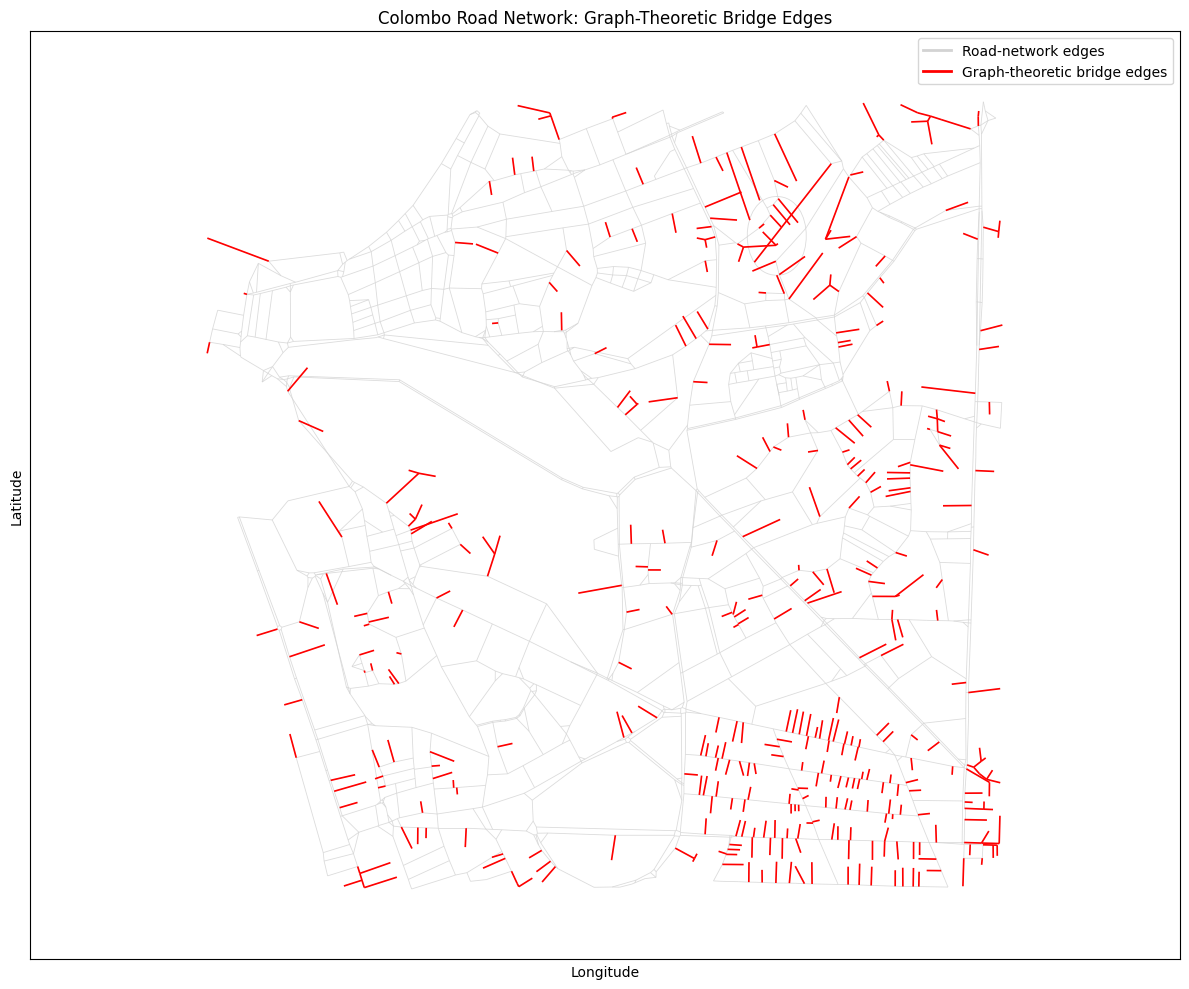

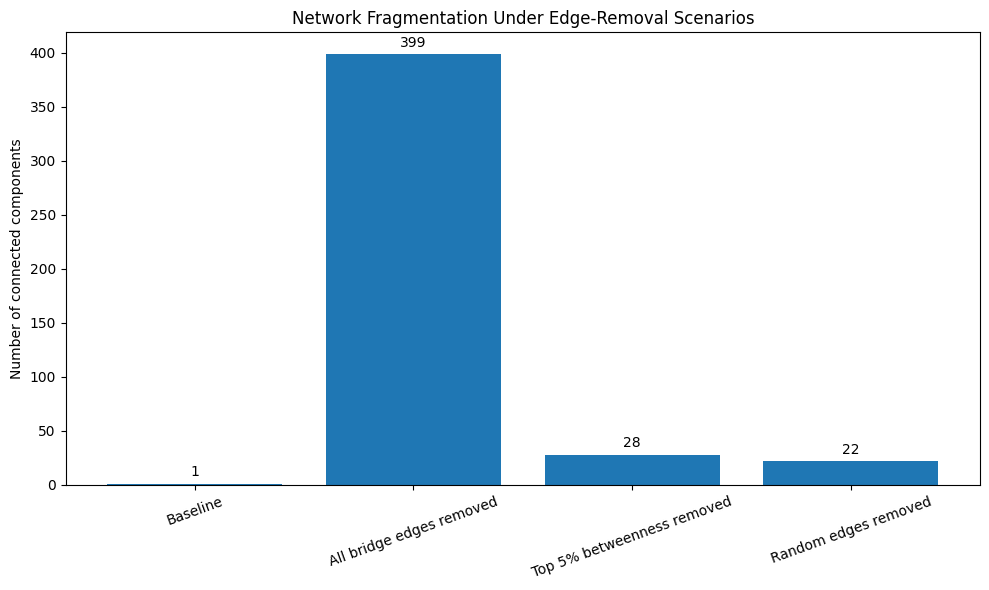

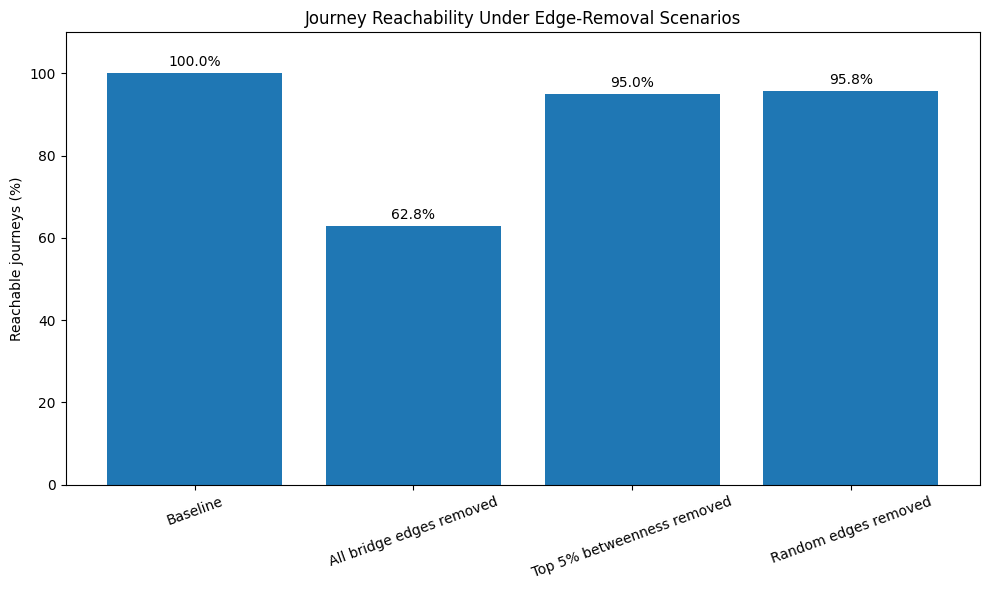

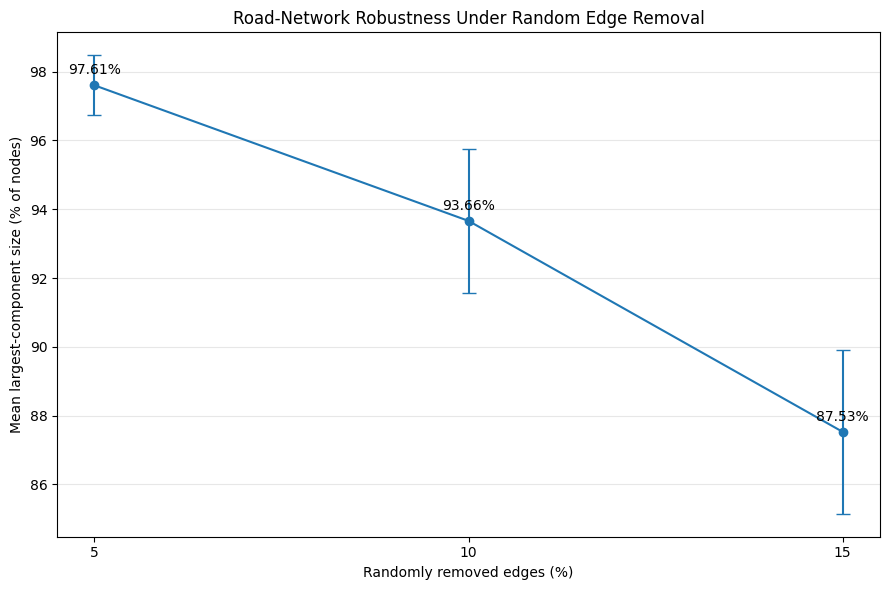

Improved figures saved in: /content/improved_figures
Please check that all four figures appeared without errors.


In [19]:
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.lines import Line2D
import pandas as pd
import numpy as np
import os

os.makedirs("improved_figures", exist_ok=True)

# Fallback data recovery if notebook runtime was restarted
if 'G' not in globals():
    print("Reconstructing network graph and variables from saved CSV files...")
    nodes = pd.read_csv("colombo_nodes.csv")
    roads = pd.read_csv("colombo_roads.csv")
    bridges = pd.read_csv("colombo_bridge_edges.csv")

    G = nx.from_pandas_edgelist(roads, source="u", target="v", edge_attr=True, create_using=nx.Graph())

    nodes["osmid"] = pd.to_numeric(nodes["osmid"], errors="raise").astype("int64")
    pos = {
        int(row.osmid): (float(row.x), float(row.y))
        for row in nodes.itertuples()
        if pd.notna(row.x) and pd.notna(row.y)
    }

    calculated_bridges = {frozenset((u, v)) for u, v in nx.bridges(G)}
    mapped_edges = [(u, v) for u, v in G.edges() if u in pos and v in pos]
    mapped_bridges = [(u, v) for u, v in calculated_bridges if u in pos and v in pos]

if 'comparison_df' not in globals():
    comparison_df = pd.read_csv("network_closure_comparison.csv")

if 'journey_df' not in globals():
    journey_df = pd.read_csv("journey_reachability_results.csv")

if 'random_summary' not in globals():
    random_summary = pd.read_csv("random_closure_summary.csv")

# --------------------------------------------------
# FIGURE 1: ROAD NETWORK AND GRAPH-THEORETIC BRIDGES
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 10))

nx.draw_networkx_edges(
    G, pos,
    edgelist=mapped_edges,
    edge_color="lightgray",
    width=0.6,
    alpha=0.8,
    ax=ax
)

nx.draw_networkx_edges(
    G, pos,
    edgelist=mapped_bridges,
    edge_color="red",
    width=1.2,
    ax=ax
)

legend_items = [
    Line2D([0], [0], color="lightgray", lw=2,
           label="Road-network edges"),
    Line2D([0], [0], color="red", lw=2,
           label="Graph-theoretic bridge edges")
]

ax.legend(handles=legend_items, loc="upper right")
ax.set_title("Colombo Road Network: Graph-Theoretic Bridge Edges")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal", adjustable="datalim")
plt.tight_layout()
plt.savefig(
    "improved_figures/figure1_bridge_map.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


# --------------------------------------------------
# FIGURE 2: CONNECTED COMPONENTS
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    comparison_df["scenario"],
    comparison_df["connected_components"]
)

ax.bar_label(bars, fmt="%.0f", padding=3)
ax.set_ylabel("Number of connected components")
ax.set_title("Network Fragmentation Under Edge-Removal Scenarios")
ax.tick_params(axis="x", labelrotation=20)
plt.tight_layout()
plt.savefig(
    "improved_figures/figure2_network_fragmentation.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


# --------------------------------------------------
# FIGURE 3: JOURNEY REACHABILITY
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    journey_df["scenario"],
    journey_df["reachability_percent"]
)

ax.bar_label(
    bars,
    labels=[
        f"{value:.1f}%"
        for value in journey_df["reachability_percent"]
    ],
    padding=3
)

ax.set_ylabel("Reachable journeys (%)")
ax.set_ylim(0, 110)
ax.set_title("Journey Reachability Under Edge-Removal Scenarios")
ax.tick_params(axis="x", labelrotation=20)
plt.tight_layout()
plt.savefig(
    "improved_figures/figure3_journey_reachability.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


# --------------------------------------------------
# FIGURE 4: RANDOM-CLOSURE ROBUSTNESS
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6))

x = random_summary["closure_fraction"] * 100
y = random_summary["mean_largest_component_percent"]
error = random_summary["std_largest_component_percent"]

ax.errorbar(
    x, y,
    yerr=error,
    marker="o",
    capsize=5
)

for xi, yi in zip(x, y):
    ax.annotate(
        f"{yi:.2f}%",
        (xi, yi),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

ax.set_xlabel("Randomly removed edges (%)")
ax.set_ylabel("Mean largest-component size (% of nodes)")
ax.set_title("Road-Network Robustness Under Random Edge Removal")
ax.set_xticks([5, 10, 15])
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(
    "improved_figures/figure4_random_robustness.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


# --------------------------------------------------
# SAVE THE FOUR IMPROVED FIGURES
# --------------------------------------------------
print("Improved figures saved in:", os.path.abspath("improved_figures"))
print("Please check that all four figures appeared without errors.")

In [20]:
import pandas as pd
import networkx as nx
import os
from google.colab import files

required_files = ["colombo_roads.csv", "colombo_nodes.csv", "colombo_bridge_edges.csv"]
missing_files = [f for f in required_files if not os.path.exists(f)]

if missing_files:
    print(f"Missing files: {missing_files}. Please upload them.")
    uploaded = files.upload()

# Load the road data and rebuild the graph safely
roads = pd.read_csv("colombo_roads.csv")
G = nx.from_pandas_edgelist(
    roads,
    source="u",
    target="v",
    edge_attr=True,
    create_using=nx.Graph()
)

print("Graph rebuilt successfully!")
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())
print("Is connected:", nx.is_connected(G))

Graph rebuilt successfully!
Number of nodes: 1737
Number of edges: 2318
Is connected: True


In [21]:
import pandas as pd
import networkx as nx

# Load the saved bridge-edge file
bridges = pd.read_csv("/content/colombo_bridge_edges.csv")

# Calculate bridges directly from the graph
calculated_bridges = {
    frozenset((u, v))
    for u, v in nx.bridges(G)
}

# Read the saved bridge edges
saved_bridges = {
    frozenset((int(u), int(v)))
    for u, v in bridges[
        ["from_node", "to_node"]
    ].itertuples(index=False, name=None)
}

# Compare the two sets
print("BRIDGE VALIDATION")
print("-----------------")
print("Calculated bridge edges:", len(calculated_bridges))
print("Saved bridge edges:", len(saved_bridges))
print(
    "Matching bridge edges:",
    len(calculated_bridges & saved_bridges)
)
print(
    "Exact match:",
    calculated_bridges == saved_bridges
)

BRIDGE VALIDATION
-----------------
Calculated bridge edges: 398
Saved bridge edges: 398
Matching bridge edges: 398
Exact match: True


In [22]:
import numpy as np, pandas as pd, networkx as nx, random, time
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.spatial import cKDTree
from scipy.optimize import milp, LinearConstraint, Bounds
from scipy.sparse import lil_matrix, csr_matrix
from scipy.stats import spearmanr
plt.rcParams.update({"font.size":10,"axes.spines.top":False,"axes.spines.right":False,"figure.dpi":120})

nodes = pd.read_csv("colombo_nodes.csv"); roads = pd.read_csv("colombo_roads.csv")
pos = {int(r.osmid):(r.x, r.y) for r in nodes.itertuples()}

# Undirected simple graph, shortest length kept for parallel records, self-loops dropped
G = nx.Graph()
for r in roads.itertuples():
    if r.u == r.v: continue
    L = float(r.length)
    if G.has_edge(r.u, r.v): G[r.u][r.v]["length"] = min(G[r.u][r.v]["length"], L)
    else: G.add_edge(r.u, r.v, length=L, name=r.name)
n, m = G.number_of_nodes(), G.number_of_edges()
P = n*(n-1)/2
print("nodes", n, "edges", m, "connected", nx.is_connected(G))

# Bridges and the number of nodes each one cuts off (smaller side)
bridges = list(nx.bridges(G)); B = len(bridges)
imp = {}
for u, v in bridges:
    H = G.copy(); H.remove_edge(u, v)
    s = len(nx.node_connected_component(H, u)); imp[(u, v)] = min(s, n-s)
bi = pd.DataFrame([{"u":u,"v":v,"nodes_cut_off":imp[(u,v)]} for u,v in bridges])
print("bridges", B, "| stubs (cut off 1 node):", (bi.nodes_cut_off==1).sum())
w = np.array([imp[b]*(n-imp[b])/P for b in bridges])      # pair loss of each bridge
print("Phi (total vulnerability) =", round(w.sum(), 4))

# Bridge-block tree
bridge_set = set(frozenset(b) for b in bridges)
H = G.copy(); H.remove_edges_from(bridges)
blocks = list(nx.connected_components(H))
comp = {x:i for i,c in enumerate(blocks) for x in c}
T = nx.Graph(); T.add_nodes_from(range(len(blocks)))
for u, v in bridges: T.add_edge(comp[u], comp[v], bridge=(u, v))
leaves = sum(1 for x in T if T.degree(x)==1)
print("blocks", len(blocks), "| tree leaves", leaves, "| lower bound ceil(L/2) =", int(np.ceil(leaves/2)))

nodes 1737 edges 2317 connected True
bridges 398 | stubs (cut off 1 node): 357
Phi (total vulnerability) = 0.5846
blocks 399 | tree leaves 357 | lower bound ceil(L/2) = 179


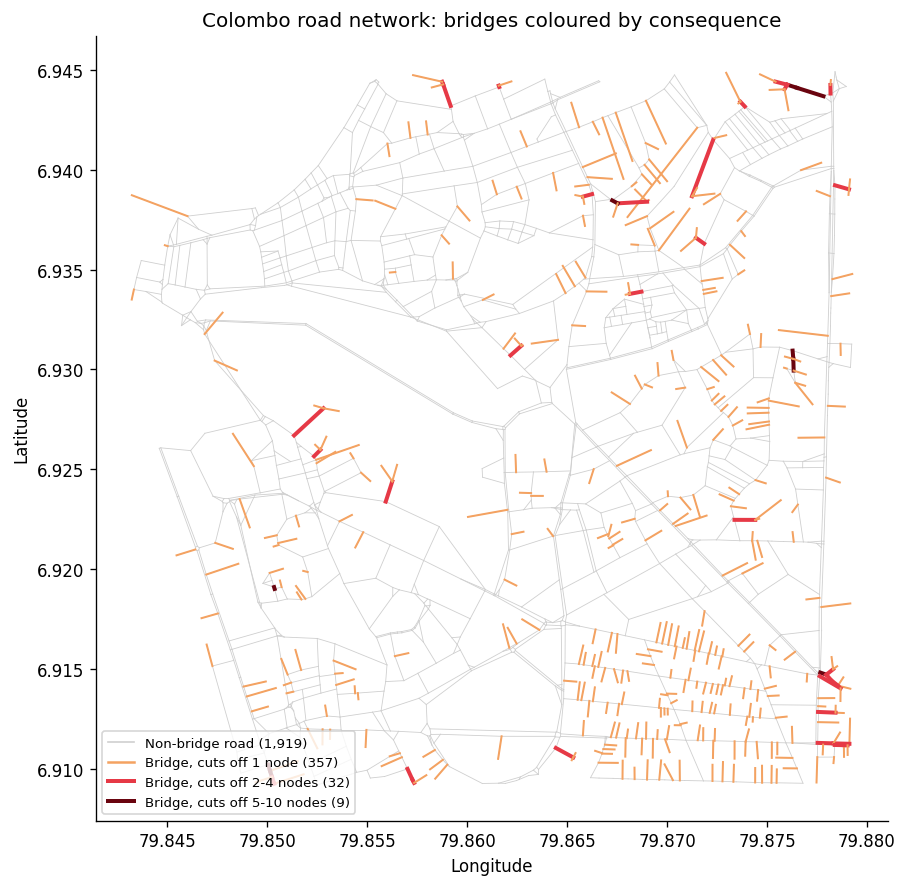

In [23]:
fig, ax = plt.subplots(figsize=(8,7.5))
for u, v in G.edges():
    ax.plot([pos[u][0],pos[v][0]],[pos[u][1],pos[v][1]], color="#cfcfcf", lw=.5, zorder=1)
for r in bi.itertuples():
    s = r.nodes_cut_off
    c = "#f4a261" if s==1 else ("#e63946" if s<=4 else "#6a040f")
    ax.plot([pos[r.u][0],pos[r.v][0]],[pos[r.u][1],pos[r.v][1]], color=c, lw=1.2 if s==1 else 2.4, zorder=2)
n1=(bi.nodes_cut_off==1).sum(); n2=bi.nodes_cut_off.between(2,4).sum(); n3=(bi.nodes_cut_off>=5).sum()
ax.legend(handles=[Line2D([0],[0],color="#cfcfcf",lw=1,label=f"Non-bridge road ({m-B:,})"),
                   Line2D([0],[0],color="#f4a261",lw=1.5,label=f"Bridge, cuts off 1 node ({n1})"),
                   Line2D([0],[0],color="#e63946",lw=2.4,label=f"Bridge, cuts off 2-4 nodes ({n2})"),
                   Line2D([0],[0],color="#6a040f",lw=2.4,label=f"Bridge, cuts off 5-10 nodes ({n3})")],
          loc="lower left", fontsize=8)
ax.set_aspect("equal"); ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("Colombo road network: bridges coloured by consequence")
plt.tight_layout(); plt.savefig("fig1_bridge_map.png", dpi=150); plt.show()

In [24]:
import numpy as np, pandas as pd, networkx as nx, random, time
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.spatial import cKDTree
from scipy.optimize import milp, LinearConstraint, Bounds
from scipy.sparse import lil_matrix, csr_matrix
from scipy.stats import spearmanr
plt.rcParams.update({"font.size":10,"axes.spines.top":False,"axes.spines.right":False,"figure.dpi":120})

nodes = pd.read_csv("colombo_nodes.csv"); roads = pd.read_csv("colombo_roads.csv")
pos = {int(r.osmid):(r.x, r.y) for r in nodes.itertuples()}

# Undirected simple graph, shortest length kept for parallel records, self-loops dropped
G = nx.Graph()
for r in roads.itertuples():
    if r.u == r.v: continue
    L = float(r.length)
    if G.has_edge(r.u, r.v): G[r.u][r.v]["length"] = min(G[r.u][r.v]["length"], L)
    else: G.add_edge(r.u, r.v, length=L, name=r.name)
n, m = G.number_of_nodes(), G.number_of_edges()
P = n*(n-1)/2
print("nodes", n, "edges", m, "connected", nx.is_connected(G))

# Bridges and the number of nodes each one cuts off (smaller side)
bridges = list(nx.bridges(G)); B = len(bridges)
imp = {}
for u, v in bridges:
    H = G.copy(); H.remove_edge(u, v)
    s = len(nx.node_connected_component(H, u)); imp[(u, v)] = min(s, n-s)
bi = pd.DataFrame([{"u":u,"v":v,"nodes_cut_off":imp[(u,v)]} for u,v in bridges])
print("bridges", B, "| stubs (cut off 1 node):", (bi.nodes_cut_off==1).sum())
w = np.array([imp[b]*(n-imp[b])/P for b in bridges])      # pair loss of each bridge
print("Phi (total vulnerability) =", round(w.sum(), 4))

# Bridge-block tree
bridge_set = set(frozenset(b) for b in bridges)
H = G.copy(); H.remove_edges_from(bridges)
blocks = list(nx.connected_components(H))
comp = {x:i for i,c in enumerate(blocks) for x in c}
T = nx.Graph(); T.add_nodes_from(range(len(blocks)))
for u, v in bridges: T.add_edge(comp[u], comp[v], bridge=(u, v))
leaves = sum(1 for x in T if T.degree(x)==1)
print("blocks", len(blocks), "| tree leaves", leaves, "| lower bound ceil(L/2) =", int(np.ceil(leaves/2)))

nodes 1737 edges 2317 connected True
bridges 398 | stubs (cut off 1 node): 357
Phi (total vulnerability) = 0.5846
blocks 399 | tree leaves 357 | lower bound ceil(L/2) = 179


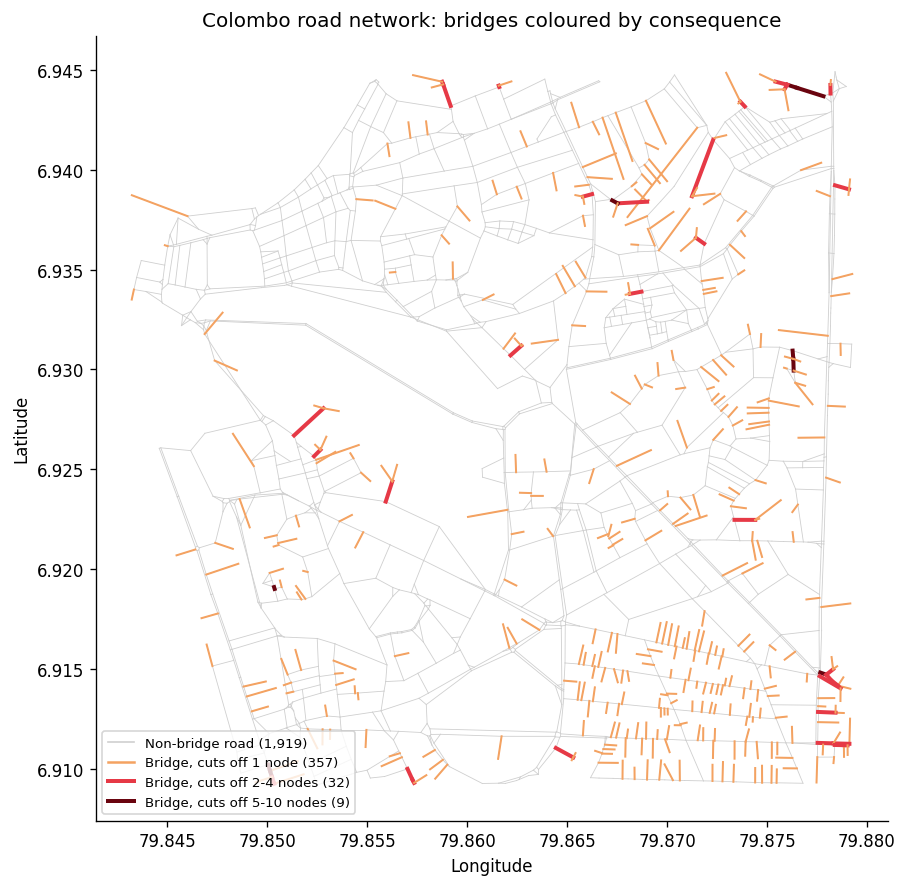

In [25]:
fig, ax = plt.subplots(figsize=(8,7.5))
for u, v in G.edges():
    ax.plot([pos[u][0],pos[v][0]],[pos[u][1],pos[v][1]], color="#cfcfcf", lw=.5, zorder=1)
for r in bi.itertuples():
    s = r.nodes_cut_off
    c = "#f4a261" if s==1 else ("#e63946" if s<=4 else "#6a040f")
    ax.plot([pos[r.u][0],pos[r.v][0]],[pos[r.u][1],pos[r.v][1]], color=c, lw=1.2 if s==1 else 2.4, zorder=2)
n1=(bi.nodes_cut_off==1).sum(); n2=bi.nodes_cut_off.between(2,4).sum(); n3=(bi.nodes_cut_off>=5).sum()
ax.legend(handles=[Line2D([0],[0],color="#cfcfcf",lw=1,label=f"Non-bridge road ({m-B:,})"),
                   Line2D([0],[0],color="#f4a261",lw=1.5,label=f"Bridge, cuts off 1 node ({n1})"),
                   Line2D([0],[0],color="#e63946",lw=2.4,label=f"Bridge, cuts off 2-4 nodes ({n2})"),
                   Line2D([0],[0],color="#6a040f",lw=2.4,label=f"Bridge, cuts off 5-10 nodes ({n3})")],
          loc="lower left", fontsize=8)
ax.set_aspect("equal"); ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("Colombo road network: bridges coloured by consequence")
plt.tight_layout(); plt.savefig("fig1_bridge_map.png", dpi=150); plt.show()

Spearman hop vs weighted EBC: 0.56
top-5% overlap: 0.43 | bridges in top 5%: 0


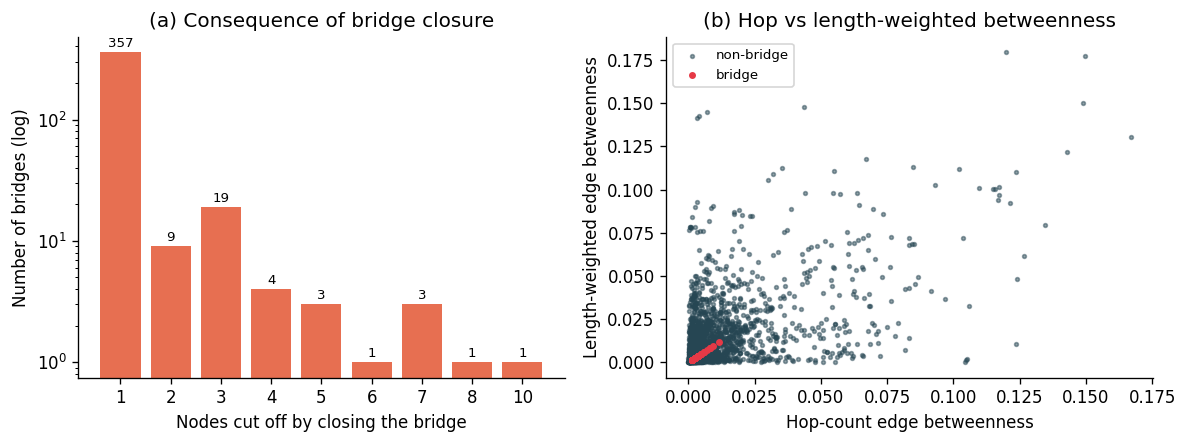

In [26]:
ebc_u = nx.edge_betweenness_centrality(G, normalized=True)                    # hop count
ebc_w = nx.edge_betweenness_centrality(G, normalized=True, weight="length")   # length weighted
get = lambda d,e: d[e] if e in d else d[(e[1],e[0])]
edges = list(G.edges())
E = pd.DataFrame({"u":[e[0] for e in edges],"v":[e[1] for e in edges],
                  "ebc_u":[get(ebc_u,e) for e in edges],"ebc_w":[get(ebc_w,e) for e in edges],
                  "is_bridge":[frozenset(e) in bridge_set for e in edges]})
print("Spearman hop vs weighted EBC:", round(spearmanr(E.ebc_u,E.ebc_w)[0],2))
k = int(.05*m)
top_u = set(E.sort_values("ebc_u",ascending=False).head(k).index); top_w = set(E.sort_values("ebc_w",ascending=False).head(k).index)
print("top-5% overlap:", round(len(top_u&top_w)/k,2), "| bridges in top 5%:", E.loc[list(top_u|top_w)].is_bridge.sum())

fig, ax = plt.subplots(1,2, figsize=(10,3.8))
vc = bi.nodes_cut_off.value_counts().sort_index()
ax[0].bar(vc.index.astype(str), vc.values, color="#e76f51"); ax[0].set_yscale("log")
ax[0].set_xlabel("Nodes cut off by closing the bridge"); ax[0].set_ylabel("Number of bridges (log)")
ax[0].set_title("(a) Consequence of bridge closure")
for x,y in zip(vc.index.astype(str), vc.values): ax[0].text(x, y*1.1, str(y), ha="center", fontsize=8)
nb_ = E[~E.is_bridge]; br_ = E[E.is_bridge]
ax[1].scatter(nb_.ebc_u, nb_.ebc_w, s=5, alpha=.5, c="#264653", label="non-bridge")
ax[1].scatter(br_.ebc_u, br_.ebc_w, s=10, c="#e63946", label="bridge")
ax[1].set_xlabel("Hop-count edge betweenness"); ax[1].set_ylabel("Length-weighted edge betweenness")
ax[1].set_title("(b) Hop vs length-weighted betweenness"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("fig2_impact_betweenness.png", dpi=150); plt.show()

mean trip (m): 2595


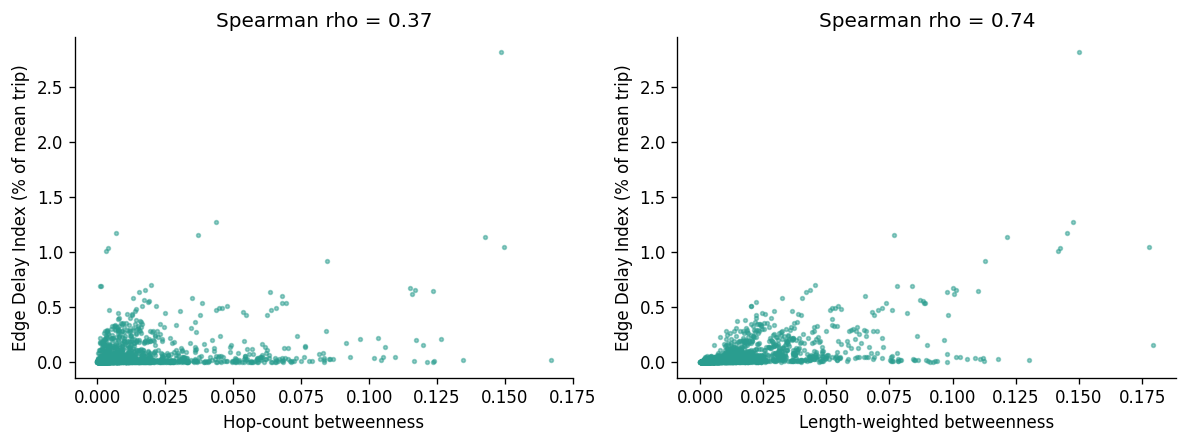

In [27]:
rng = random.Random(42); ids = list(G.nodes)
pairs = [tuple(rng.sample(ids, 2)) for _ in range(1500)]
base, usage = {}, {}
for p in pairs:
    path = nx.dijkstra_path(G, p[0], p[1], weight="length")
    base[p] = nx.path_weight(G, path, "length")
    for a, b in zip(path[:-1], path[1:]): usage.setdefault(frozenset((a,b)), []).append(p)
mean_trip = np.mean(list(base.values())); print("mean trip (m):", round(mean_trip))

edi = {}
for e, ps in usage.items():
    a, b = tuple(e); data = G[a][b]; G.remove_edge(a, b); extra = 0
    for p in ps:
        try: extra += nx.dijkstra_path_length(G, p[0], p[1], weight="length") - base[p]
        except nx.NetworkXNoPath: pass
    G.add_edge(a, b, **data); edi[e] = extra/len(pairs)
D = pd.DataFrame([{"u":tuple(e)[0],"v":tuple(e)[1],"edi_pct":100*val/mean_trip} for e,val in edi.items()])
D["is_bridge"] = [frozenset((r.u,r.v)) in bridge_set for r in D.itertuples()]
D["ebc_u"] = [get(ebc_u,(r.u,r.v)) for r in D.itertuples()]
D["ebc_w"] = [get(ebc_w,(r.u,r.v)) for r in D.itertuples()]
nb_ = D[~D.is_bridge]
fig, ax = plt.subplots(1,2, figsize=(10,3.8))
for a, col, t in [(ax[0],"ebc_u","Hop-count betweenness"),(ax[1],"ebc_w","Length-weighted betweenness")]:
    a.scatter(nb_[col], nb_.edi_pct, s=5, alpha=.5, c="#2a9d8f")
    a.set_xlabel(t); a.set_ylabel("Edge Delay Index (% of mean trip)")
    a.set_title(f"Spearman rho = {spearmanr(nb_[col], nb_.edi_pct)[0]:.2f}")
plt.tight_layout(); plt.savefig("fig3_edi.png", dpi=150); plt.show()

In [28]:
ids = list(G.nodes)
lon = np.array([pos[i][0] for i in ids]); lat = np.array([pos[i][1] for i in ids])
X = (lon-lon.mean())*111320*np.cos(np.radians(6.925)); Y = (lat-lat.mean())*110574
tree = cKDTree(np.c_[X, Y])
R = 500
cand = []
for i, j in tree.query_pairs(R):
    a, b = ids[i], ids[j]
    if comp[a]==comp[b] or G.has_edge(a, b): continue
    d = float(np.hypot(X[i]-X[j], Y[i]-Y[j]))
    path = nx.shortest_path(T, comp[a], comp[b])
    cover = [T[path[k]][path[k+1]]["bridge"] for k in range(len(path)-1)]
    cand.append((a, b, 1.2*d, cover))
Cn = len(cand); print("candidate links:", Cn)

bidx = {frozenset(b):i for i,b in enumerate(bridges)}
A = lil_matrix((B, Cn))
for j, (a,b,c,cv) in enumerate(cand):
    for e in cv: A[bidx[frozenset(e)], j] = 1
A = csr_matrix(A); cost = np.array([c[2] for c in cand])

def solve(obj):
    return milp(obj, constraints=LinearConstraint(A, lb=np.ones(B)), integrality=np.ones(Cn),
                bounds=Bounds(0,1), options={"time_limit":120})
r1 = solve(np.ones(Cn)); sel_count  = [j for j in range(Cn) if r1.x[j]>.5]
r2 = solve(cost);        sel_length = [j for j in range(Cn) if r2.x[j]>.5]
print(f"min #links : {len(sel_count)} links, {cost[sel_count].sum()/1000:.1f} km")
print(f"min length : {len(sel_length)} links, {cost[sel_length].sum()/1000:.1f} km")

candidate links: 34891
min #links : 179 links, 68.3 km
min length : 220 links, 18.6 km


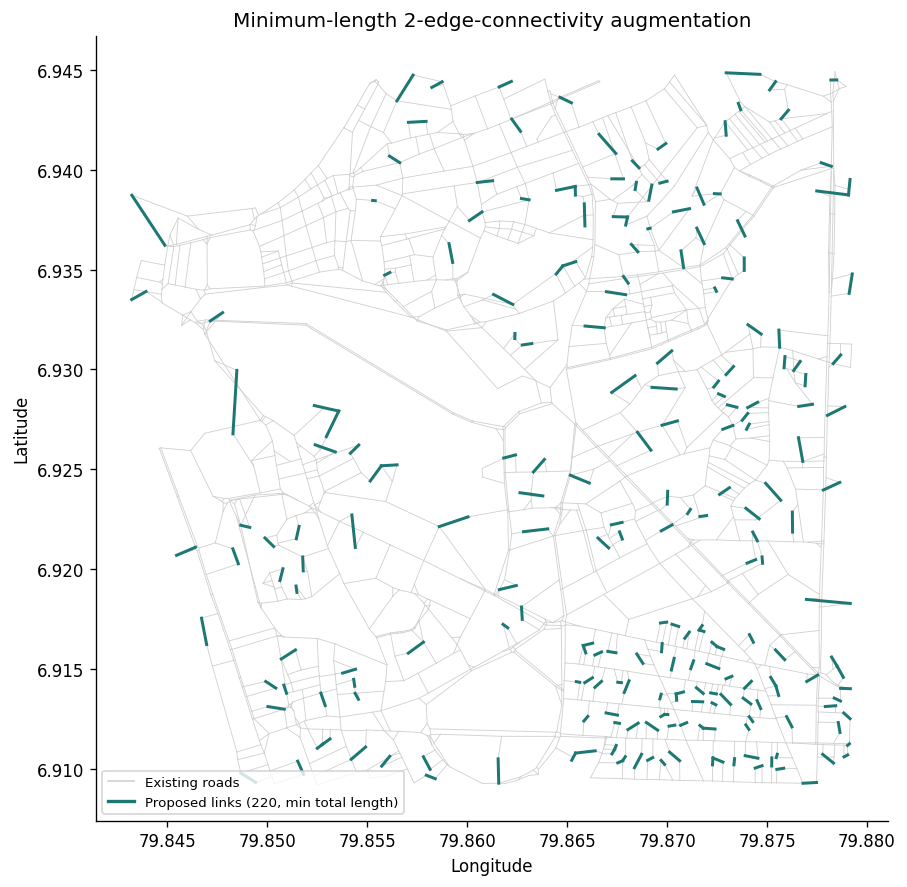

In [29]:
fig, ax = plt.subplots(figsize=(8,7.5))
for u, v in G.edges():
    ax.plot([pos[u][0],pos[v][0]],[pos[u][1],pos[v][1]], color="#cfcfcf", lw=.5, zorder=1)
for j in sel_length:
    a, b, _, _ = cand[j]
    ax.plot([pos[a][0],pos[b][0]],[pos[a][1],pos[b][1]], color="#1d7874", lw=1.8, zorder=3)
ax.legend(handles=[Line2D([0],[0],color="#cfcfcf",lw=1,label="Existing roads"),
                   Line2D([0],[0],color="#1d7874",lw=2,label=f"Proposed links ({len(sel_length)}, min total length)")],
          loc="lower left", fontsize=8)
ax.set_aspect("equal"); ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("Minimum-length 2-edge-connectivity augmentation")
plt.tight_layout(); plt.savefig("fig4_augmentation_map.png", dpi=150); plt.show()

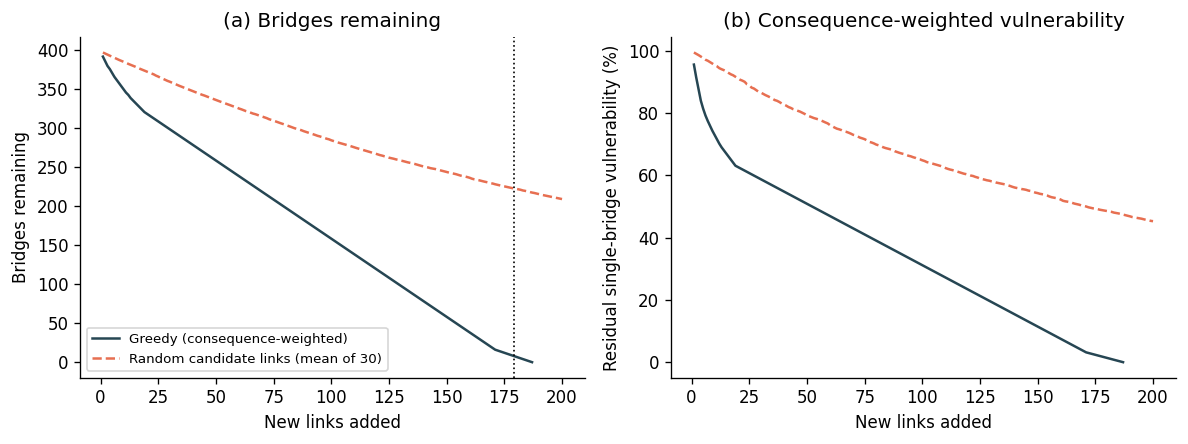

50% of Phi removed with 53 greedy links
80% of Phi removed with 129 greedy links
90% of Phi removed with 154 greedy links
95% of Phi removed with 167 greedy links


In [30]:
K = 200; Ad = A.tocsc()
covered = np.zeros(B, bool); hist = []
for k in range(K):                                   # greedy: weighted coverage
    gain = Ad.T.dot((~covered)*(w+1e-9)); j = int(np.argmax(gain))
    if gain[j] <= 0: break
    covered |= Ad[:, j].toarray().ravel() > 0
    hist.append((k+1, covered.sum(), w[~covered].sum()))
hG = pd.DataFrame(hist, columns=["links","covered","loss_left"])

rg = np.random.default_rng(42); runs = []
for rep in range(30):                                # random baseline, 30 draws
    order = rg.permutation(Cn); cov = np.zeros(B, bool); h = []
    for k in range(K):
        cov |= A[:, order[k]].toarray().ravel() > 0; h.append((cov.sum(), w[~cov].sum()))
    runs.append(h)
hR = np.array(runs).mean(0); w0 = w.sum()

fig, ax = plt.subplots(1,2, figsize=(10,3.8))
ax[0].plot(hG.links, B-hG.covered, c="#264653", label="Greedy (consequence-weighted)")
ax[0].plot(np.arange(1,K+1), B-hR[:,0], c="#e76f51", ls="--", label="Random candidate links (mean of 30)")
ax[0].axvline(int(np.ceil(leaves/2)), c="k", ls=":", lw=1)
ax[0].set_xlabel("New links added"); ax[0].set_ylabel("Bridges remaining"); ax[0].set_title("(a) Bridges remaining"); ax[0].legend(fontsize=8)
ax[1].plot(hG.links, 100*hG.loss_left/w0, c="#264653"); ax[1].plot(np.arange(1,K+1), 100*hR[:,1]/w0, c="#e76f51", ls="--")
ax[1].set_xlabel("New links added"); ax[1].set_ylabel("Residual single-bridge vulnerability (%)")
ax[1].set_title("(b) Consequence-weighted vulnerability")
plt.tight_layout(); plt.savefig("fig5_budget_curve.png", dpi=150); plt.show()
for f in (.5,.8,.9,.95):
    row = hG[hG.loss_left <= (1-f)*w0].iloc[0]; print(f"{int(f*100)}% of Phi removed with {int(row.links)} greedy links")

bridges left | optimised: 0 | random links: 216
                 scenario  frac  comp  comp_sd   lcc  lcc_sd
                 Baseline  0.05 23.15     3.98 97.61    1.03
                 Baseline  0.10 52.25     5.84 93.24    2.00
                 Baseline  0.15 87.33     7.07 86.48    2.90
    Optimised links (ILP)  0.05  2.62     1.14 99.85    0.14
    Optimised links (ILP)  0.10 10.33     2.92 99.06    0.35
    Optimised links (ILP)  0.15 23.80     4.54 97.34    0.84
Random links (same count)  0.05 13.03     3.20 99.14    0.28
Random links (same count)  0.10 28.18     4.45 97.92    0.47
Random links (same count)  0.15 48.03     5.26 96.08    0.66


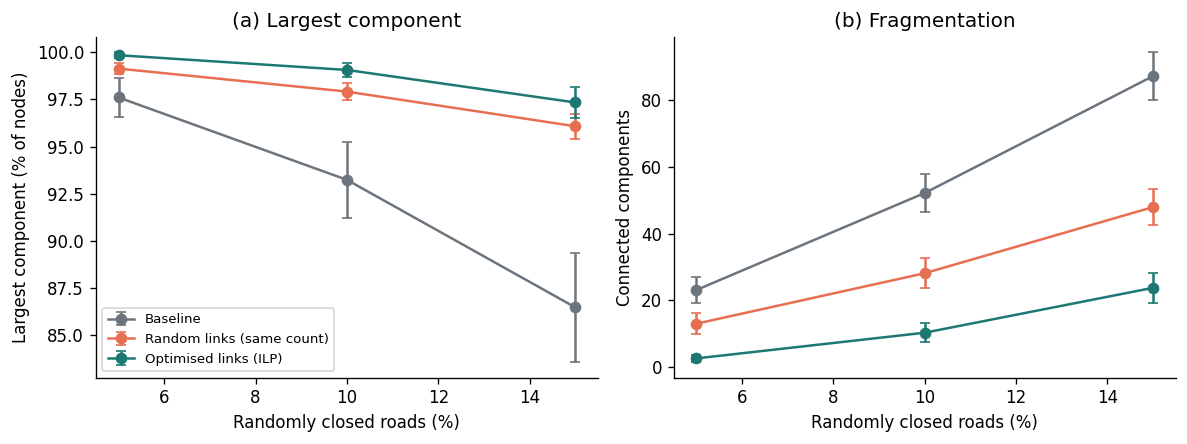

In [31]:
def add_links(sel):
    g = G.copy()
    for j in sel:
        a, b, c, _ = cand[j]; g.add_edge(a, b, length=c)
    return g
def lcc_stats(g):
    cc = list(nx.connected_components(g)); return len(cc), 100*max(len(c) for c in cc)/g.number_of_nodes()

G_opt  = add_links(sel_count)                                          # 179 optimised links
rr = np.random.default_rng(7)
G_rand = add_links(list(rr.choice(Cn, size=len(sel_count), replace=False)))   # same number, random
print("bridges left | optimised:", len(list(nx.bridges(G_opt))), "| random links:", len(list(nx.bridges(G_rand))))

random.seed(42); rows = []
for name, g in [("Baseline",G),("Random links (same count)",G_rand),("Optimised links (ILP)",G_opt)]:
    Eg = list(g.edges())
    for frac in (0.05, 0.10, 0.15):
        for rep in range(100):
            h = g.copy(); h.remove_edges_from(random.sample(Eg, int(len(Eg)*frac)))
            nc, lc = lcc_stats(h); rows.append((name, frac, nc, lc))
rd = pd.DataFrame(rows, columns=["scenario","frac","components","lcc"])
sm = rd.groupby(["scenario","frac"]).agg(comp=("components","mean"),comp_sd=("components","std"),
                                          lcc=("lcc","mean"),lcc_sd=("lcc","std")).reset_index()
print(sm.round(2).to_string(index=False))

fig, ax = plt.subplots(1,2, figsize=(10,3.8))
for name, c in [("Baseline","#6c757d"),("Random links (same count)","#e76f51"),("Optimised links (ILP)","#1d7874")]:
    d = sm[sm.scenario==name]
    ax[0].errorbar(d.frac*100, d.lcc,  yerr=d.lcc_sd,  marker="o", capsize=3, label=name, c=c)
    ax[1].errorbar(d.frac*100, d.comp, yerr=d.comp_sd, marker="o", capsize=3, label=name, c=c)
ax[0].set_xlabel("Randomly closed roads (%)"); ax[0].set_ylabel("Largest component (% of nodes)"); ax[0].set_title("(a) Largest component"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("Randomly closed roads (%)"); ax[1].set_ylabel("Connected components"); ax[1].set_title("(b) Fragmentation")
plt.tight_layout(); plt.savefig("fig6_robustness.png", dpi=150); plt.show()